# 10 · Extension: the probe subsystem

**Why a second subsystem.** In coolant every injected root cause is a variable that never changes in normal operation. Its first change is then maximally surprising whatever its parents are, so root cause analysis (RCA) was perfect even without any graph (notebooks 06 and 09). The probe subsystem is the opposite case:
- Its root causes (`MPA_InitPos`, `MPA_WorkPos`, the end-position sensors of the measuring-probe arm) switch all the time during normal machining.
- The faults are sensor defects: a sensor that stays true or false although the arm was commanded to move.
- Such a fault is only visible *relative to the parents*, i.e. the movement commands `MPA_toInitPos` / `MPA_toWorkPos`.

So the graph should matter for RCA here.

**Scope.** The same, unchanged methods as notebooks 02–06 and 09, applied to probe:
- preprocessing at 0.5 s
- PCMCI+ per regime with the G² test
- graph evaluation
- SCM fit
- mechanism-break RCA (leave one scenario out)
- graph-perturbation study

**Not applicable here.** Interventions and counterfactual explanations (notebooks 07–08) are not run. Under the actionability rules, the probe variables are sensor signals and PLC commands, not component conditions that maintenance can set to a fixed healthy value. Repairing a sensor would *restore its mechanism*: a soft intervention, not do(X = constant). That is outside the implemented intervention type, so it is marked as a limitation instead of being forced.

In [1]:
import time
from dataclasses import asdict

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
from scipy import stats

from causal_rca import causal_discovery as cd
from causal_rca import data
from causal_rca import evaluation as ev
from causal_rca import graph_evaluation as ge
from causal_rca import preprocessing as pp
from causal_rca import root_cause_analysis as rca
from causal_rca import scm as sc

ev.set_plot_style()
pd.set_option('display.max_columns', 50)
pd.set_option('display.width', 180)
SUBSYSTEM = 'probe'
INTERVAL = 0.5
PRIMARY = cd.DiscoveryConfig(interval_s=INTERVAL, tau_max_s=10.0, pc_alpha=0.01)
KINDS = ['delete', 'insert', 'reverse']
FRACTIONS = [0.1, 0.25, 0.5]
SEEDS = range(5)
SEED = 0
METRICS = ['top1', 'hit@3', 'recall@3', 'ap@3', 'rr']

## 1. Preprocessing

In [2]:
# events of the normal recordings and the probe fault runs, states at 0.5 s, verification
infos = pp.discover_recordings(data.RAW_DIR)
recordings = pd.DataFrame([asdict(r) for r in infos])
runs = data.load_fault_runs()
experiments = data.load_experiments()
manipulated = data.manipulated_by_recording(runs, experiments)
expert = ge.simple_digraph(data.load_expert_graph(subsystem=SUBSYSTEM))
NODES = sorted(expert.nodes)
types = {n: ('Alarm' if expert.nodes[n]['kind'] == 'Alarm' else 'Binary') for n in NODES}
ALARMS = sorted(n for n in NODES if types[n] == 'Alarm')

normal_ids = recordings.loc[recordings.source == 'real_op', 'recording_id'].tolist()
fault_ids = runs.loc[runs.subsystem == SUBSYSTEM, 'recording_id'].tolist()
keep = set(normal_ids + fault_ids)
events = pp.parse_values(pp.load_all_events([r for r in infos if r.recording_id in keep], data.RAW_DIR))
events, _ = pp.resolve_duplicates(events)
events = pp.mark_changes(events)
states = pp.reconstruct_states(events, INTERVAL, nodes=NODES)
verification = pp.verify_states(events, states, INTERVAL)
print('verification passed:', verification.passed, f'({verification.n_cells_checked:,} cells)')

splits = data.make_splits(recordings, SUBSYSTEM)
ev.save_table(splits, f'10_{SUBSYSTEM}_splits')
normal_train = splits.loc[splits.split == 'train', 'recording_id'].tolist()
view = pp.ModelView.fit(states, pp.node_types(events), normal_train + fault_ids, 'discrete', nodes=NODES)
view_data = view.transform(states, normal_ids + fault_ids)
pp.save_view_data(view, view_data, data.PROCESSED_DIR, f'{SUBSYSTEM}_dt{INTERVAL:g}', interval_s=INTERVAL)
coverage = data.variable_coverage(events, NODES)
print('fault runs recording each variable:', coverage.loc[fault_ids].sum().to_dict())
experiments.loc[experiments.subsystem == SUBSYSTEM, ['experiment_id', 'n_runs', 'manipulated_vars', 'alarms', 'instead_failure']]

verification passed: True (2,346,267 cells)


fault runs recording each variable: {'MPA_A_701124': 22, 'MPA_A_701125': 12, 'MPA_InitPos': 34, 'MPA_WorkPos': 34, 'MPA_toInitPos': 34, 'MPA_toWorkPos': 34, 'MPC_Closed': 34, 'MPC_close': 34, 'MPC_isOpen': 34, 'MPC_open': 34, 'MP_Inactive': 34}


,experiment_id,n_runs,manipulated_vars,alarms,instead_failure
13,exp_1,6,[MPA_WorkPos],[MPA_A_701124],A) WP suddenly switches to false (spontaneous ...
14,exp_2_3,8,[MPA_InitPos],[MPA_A_701124],A) IP suddenly switches to false (spontaneous ...
15,exp_4,6,[MPA_WorkPos],[MPA_A_701125],WP incorrectly remains true even after movemen...
16,exp_5,6,[MPA_InitPos],[MPA_A_701125],IP incorrectly remains true even after movemen...
17,exp_6,3,"[MPA_InitPos, MPA_WorkPos]",[MPA_A_701124],IP remains true - no movement has occurred / t...
18,exp_7,5,"[MPA_InitPos, MPA_WorkPos]",[MPA_A_701124],WP remains true - no movement has occurred


## 2. Causal discovery (PCMCI+, same settings as coolant)

In [3]:
# pcmci+ per regime, combined graph and leave-one-scenario-out graphs
regimes = cd.define_regimes(splits)
start = time.perf_counter()
primary = cd.discover(view_data, regimes, PRIMARY)
print(f'runtime {time.perf_counter() - start:.0f} s')
folds = [r for r in regimes if r != 'normal']
edges = pd.concat([primary.edges(NODES).assign(graph_id='discovered')] +
                  [primary.edges(NODES, exclude=[f]).assign(graph_id=f'discovered_without_{f}') for f in folds],
                  ignore_index=True)
ev.save_table(primary.links, f'10_{SUBSYSTEM}_links')
ev.save_table(edges, f'10_{SUBSYSTEM}_edges')
pairs = primary.pairs(NODES)
print(pairs.decision.value_counts().to_string())
pd.DataFrame([{'regime': r, 'variables': len(res.variables), 'samples': res.n_samples, 'runtime_s': round(res.runtime_s, 1)}
              for r, res in primary.results.items()])

runtime 442 s
decision
absent        46
undirected     7
untestable     1
a -> b         1


,regime,variables,samples,runtime_s
0,normal,9,136958,413.0
1,exp_1,10,2763,5.3
2,exp_2_3,10,3588,5.4
3,exp_4,10,2959,7.7
4,exp_5,10,2603,4.5
5,exp_6,10,1239,2.7
6,exp_7,10,2035,3.6


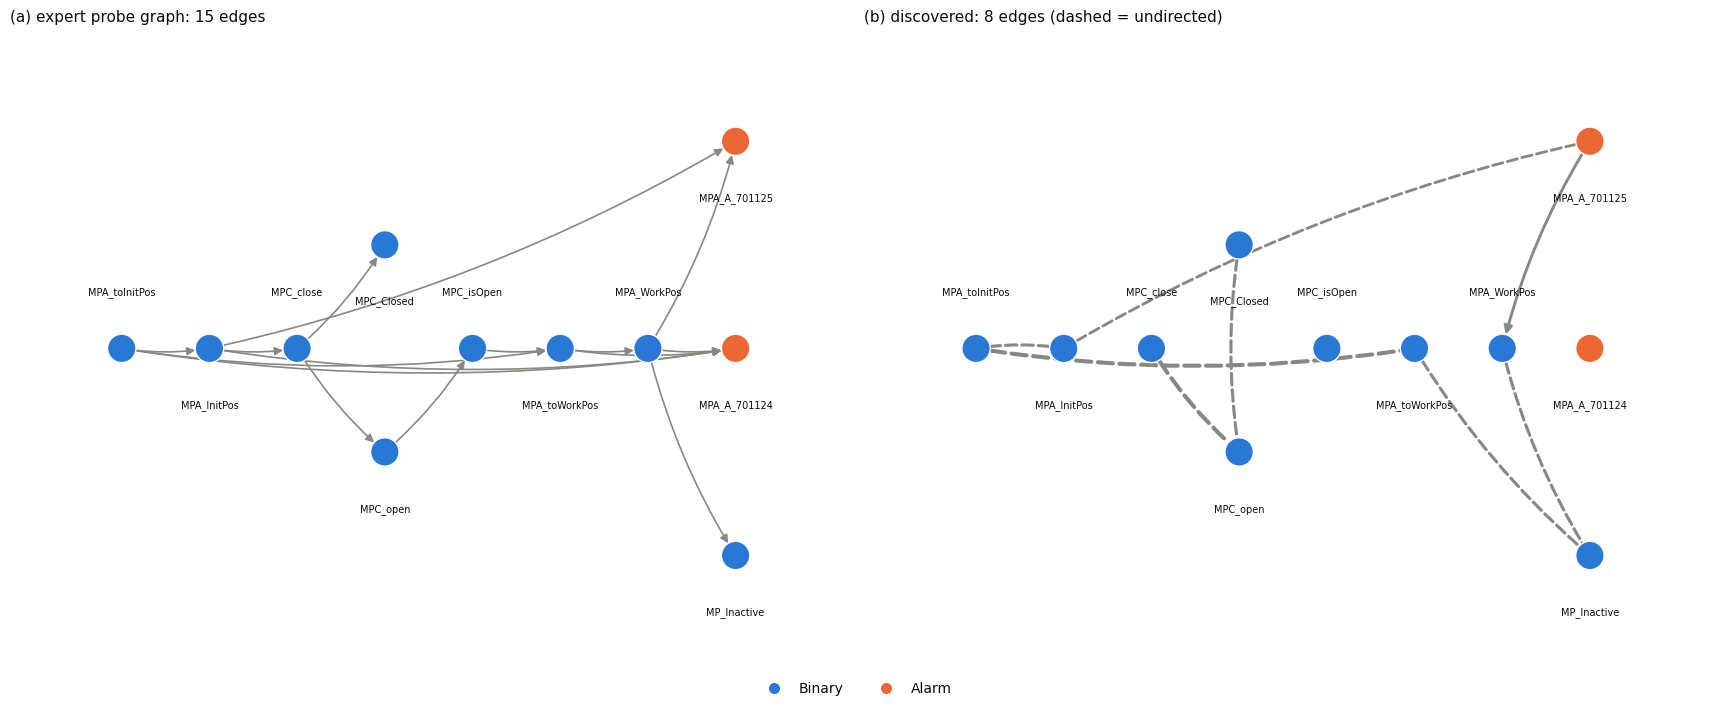

In [4]:
# figure 1: expert vs discovered probe graph
graphs = {gid: cd.edges_to_graph(g, NODES) for gid, g in edges.groupby('graph_id')}
discovered = graphs['discovered']
layout = ev.graph_layout(expert)
fig, axes = plt.subplots(1, 2, figsize=(17, 7), layout='constrained')
ev.draw_graph(expert, axes[0], node_types=types, pos=layout, title=f'(a) expert probe graph: {expert.number_of_edges()} edges')
ev.draw_graph(discovered, axes[1], node_types=types, pos=layout, width_by_support=True,
              title=f'(b) discovered: {discovered.number_of_edges()} edges (dashed = undirected)')
fig.legend(handles=ev.type_legend_handles(['Binary', 'Alarm']), loc='outside lower center', ncol=2)
ev.save_figure(fig, f'10_{SUBSYSTEM}_expert_vs_discovered')
plt.show()

## 3. Graph evaluation

In [5]:
# metrics against the expert graph and against random graphs of the same size
metrics_graph = ge.compare_graphs(discovered, expert)
random = ge.random_reference(expert, metrics_graph['n_pred_edges'], n_draws=2000, seed=SEED)
graph_table = pd.DataFrame([{'graph': 'discovered', **metrics_graph}, {'graph': 'random (mean)', **random.mean().to_dict()}])
ev.save_table(graph_table, f'10_{SUBSYSTEM}_graph_metrics')
comparison = ge.edge_comparison_table(discovered, expert)
ev.save_table(comparison, f'10_{SUBSYSTEM}_edge_comparison')
print(comparison.outcome.value_counts().to_string())
graph_table[['graph', 'n_pred_edges', 'skeleton_precision', 'skeleton_recall', 'skeleton_f1', 'directed_precision',
             'directed_recall', 'directed_f1', 'shd', 'orientation_accuracy']].round(3)

outcome
missed        9
undirected    5
extra         2
reversed      1


,graph,n_pred_edges,skeleton_precision,skeleton_recall,skeleton_f1,directed_precision,directed_recall,directed_f1,shd,orientation_accuracy
0,discovered,8.0,0.750,0.400,0.522,0.00,0.000,0.000,17.000,0.000
1,random (mean),8.0,0.276,0.147,0.192,0.14,0.075,0.097,19.674,0.505


## 4. SCM fit: does the structure explain the sensors?

In [6]:
# one-step-ahead fit on held-out normal recordings and unseen scenarios, expert vs discovered vs empty graph
discovered_dag = {gid: ge.to_dag(g)[0] for gid, g in graphs.items()}
empty = nx.DiGraph()
empty.add_nodes_from(NODES)
getters = {'expert': lambda fold: expert,
           'discovered': lambda fold: discovered_dag['discovered' if fold is None else f'discovered_without_{fold}'],
           'empty': lambda fold: empty}
held_out_normal = splits.loc[splits.split.isin(['validation', 'test']), 'recording_id'].tolist()
fit_rows = []
for g, getter in getters.items():
    model = sc.fit_scm(view_data, getter(None), data.fold_training_ids(splits, None), manipulated, INTERVAL)
    fit_rows.append(sc.summarize_predictions(sc.held_out_predictions(model, view_data, held_out_normal)).assign(graph=g, data='held-out normal'))
    preds = []
    for fold in folds:
        m = sc.fit_scm(view_data, getter(fold), data.fold_training_ids(splits, fold), manipulated, INTERVAL)
        preds.append(sc.held_out_predictions(m, view_data, splits.loc[splits.fold == fold, 'recording_id'].tolist(), manipulated))
    fit_rows.append(sc.summarize_predictions(pd.concat(preds)).assign(graph=g, data='unseen scenarios'))
fit = pd.concat(fit_rows, ignore_index=True)
ev.save_table(fit, f'10_{SUBSYSTEM}_scm_fit')
fit[fit.n_changes > 0].pivot_table(index='variable', columns=['data', 'graph'], values='p_observed_change').round(3)

data          held-out normal               unseen scenarios              
graph              discovered  empty expert       discovered  empty expert
variable                                                                  
MPA_A_701124              NaN    NaN    NaN            0.007  0.007  0.066
MPA_A_701125              NaN    NaN    NaN            0.006  0.006  0.364
MPA_InitPos             0.004  0.004  0.617            0.004  0.004  0.598
MPA_WorkPos             0.004  0.004  0.563            0.004  0.004  0.464
MPA_toInitPos           0.005  0.005  0.005            0.005  0.005  0.005
MPA_toWorkPos           0.005  0.005  0.834            0.005  0.005  0.803
MPC_Closed              0.005  0.005  0.797            0.004  0.004  0.777
MPC_close               0.005  0.005  0.357            0.004  0.004  0.299
MPC_isOpen              0.005  0.005  0.701            0.004  0.004  0.688
MPC_open                0.005  0.005  0.775            0.004  0.004  0.750
MP_Inactive             0.006  0.006  0.301            0.309  0.005  0.519

## 5. Root cause analysis

In [7]:
# leave-one-scenario-out rca with expert, discovered and empty graphs
rca_results = {g: rca.evaluate_rca(view_data, splits, manipulated, getter, ALARMS, NODES, INTERVAL, seed=SEED)
               for g, getter in {'expert': getters['expert'],
                                 'discovered': lambda fold: discovered_dag[f'discovered_without_{fold}'],
                                 'empty': getters['empty']}.items()}
summary = pd.concat([rca.summarize_rca(r[0], METRICS, seed=SEED).assign(graph=g) for g, r in rca_results.items()], ignore_index=True)
ev.save_table(summary, f'10_{SUBSYSTEM}_rca_summary')
for g, r in rca_results.items():
    ev.save_table(r[0], f'10_{SUBSYSTEM}_rca_runs_{g}')
    ev.save_table(r[1], f'10_{SUBSYSTEM}_rca_rankings_{g}')
summary.pivot(index='metric', columns='graph', values=['mean', 'ci_low', 'ci_high', 'chance']).round(3)

mean                   ci_low                  ci_high                   chance              
graph    discovered  empty expert discovered  empty expert discovered  empty expert discovered  empty expert
metric                                                                                                      
ap@3          0.559  0.444  0.475      0.480  0.395  0.328      0.642  0.498  0.627      0.212  0.212  0.212
hit@3         1.000  1.000  0.559      1.000  1.000  0.382      1.000  1.000  0.706      0.397  0.397  0.397
recall@3      1.000  1.000  0.544      1.000  1.000  0.382      1.000  1.000  0.706      0.337  0.337  0.337
rr            0.559  0.446  0.580      0.480  0.387  0.459      0.642  0.510  0.703      0.353  0.353  0.353
top1          0.235  0.088  0.441      0.088  0.000  0.294      0.382  0.206  0.588      0.142  0.142  0.142

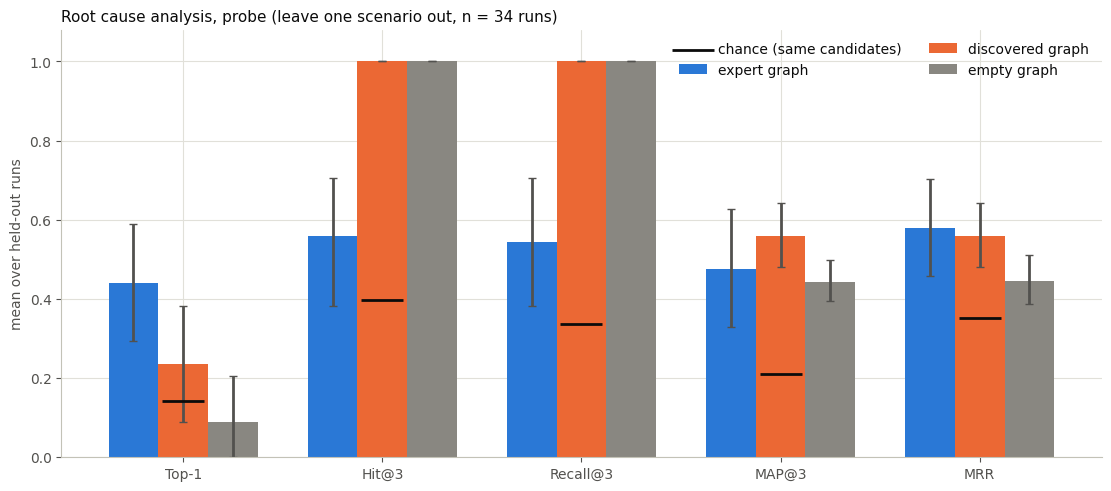

In [8]:
# figure 2: rca metrics per graph with 95% bootstrap intervals and chance
graph_colors = {'expert': ev.COLORS[0], 'discovered': ev.COLORS[1], 'empty': ev.INK['muted']}
fig, ax = plt.subplots(figsize=(11, 4.8), layout='constrained')
x = np.arange(len(METRICS))
for k, g in enumerate(rca_results):
    s = summary[summary.graph == g].set_index('metric').loc[METRICS]
    ax.bar(x + (k - 1) * 0.25, s['mean'], width=0.25, color=graph_colors[g], label=f'{g} graph',
           yerr=[s['mean'] - s.ci_low, s.ci_high - s['mean']], capsize=3, error_kw={'ecolor': ev.INK['secondary']})
chance = summary[summary.graph == 'expert'].set_index('metric').loc[METRICS, 'chance']
ax.scatter(x, chance, marker='_', s=900, color=ev.INK['primary'], zorder=4, label='chance (same candidates)')
ax.set_xticks(x, ['Top-1', 'Hit@3', 'Recall@3', 'MAP@3', 'MRR'])
ax.set_ylim(0, 1.08)
ax.set_ylabel('mean over held-out runs')
n_runs = int(rca_results['expert'][0].scored.sum())
ax.set_title(f'Root cause analysis, probe (leave one scenario out, n = {n_runs} runs)')
ax.legend(loc='upper right', ncol=2)
ev.save_figure(fig, f'10_{SUBSYSTEM}_rca_metrics')
plt.show()

In [9]:
# per-scenario map@3 and top-1 for every graph
per_scenario = pd.concat([r[0][r[0].scored].groupby('fold')[['top1', 'ap@3', 'chance_ap@3']].mean().assign(graph=g)
                          for g, r in rca_results.items()]).reset_index()
truth = experiments.set_index('experiment_id').manipulated_vars.map(', '.join)
per_scenario['true_causes'] = per_scenario.fold.map(truth)
ev.save_table(per_scenario, f'10_{SUBSYSTEM}_rca_per_scenario')
per_scenario.pivot(index=['fold', 'true_causes'], columns='graph', values=['top1', 'ap@3']).round(2)

top1                    ap@3             
graph                            discovered empty expert discovered empty expert
fold    true_causes                                                             
exp_1   MPA_WorkPos                     0.0   0.0   0.83       0.33  0.33   0.83
exp_2_3 MPA_InitPos                     0.0   0.0   0.25       0.50  0.33   0.38
exp_4   MPA_WorkPos                     0.0   0.0   0.83       0.33  0.33   0.83
exp_5   MPA_InitPos                     0.0   0.0   0.33       0.50  0.50   0.44
exp_6   MPA_InitPos, MPA_WorkPos        1.0   1.0   0.00       1.00  0.83   0.00
exp_7   MPA_InitPos, MPA_WorkPos        1.0   0.0   0.20       1.00  0.58   0.10

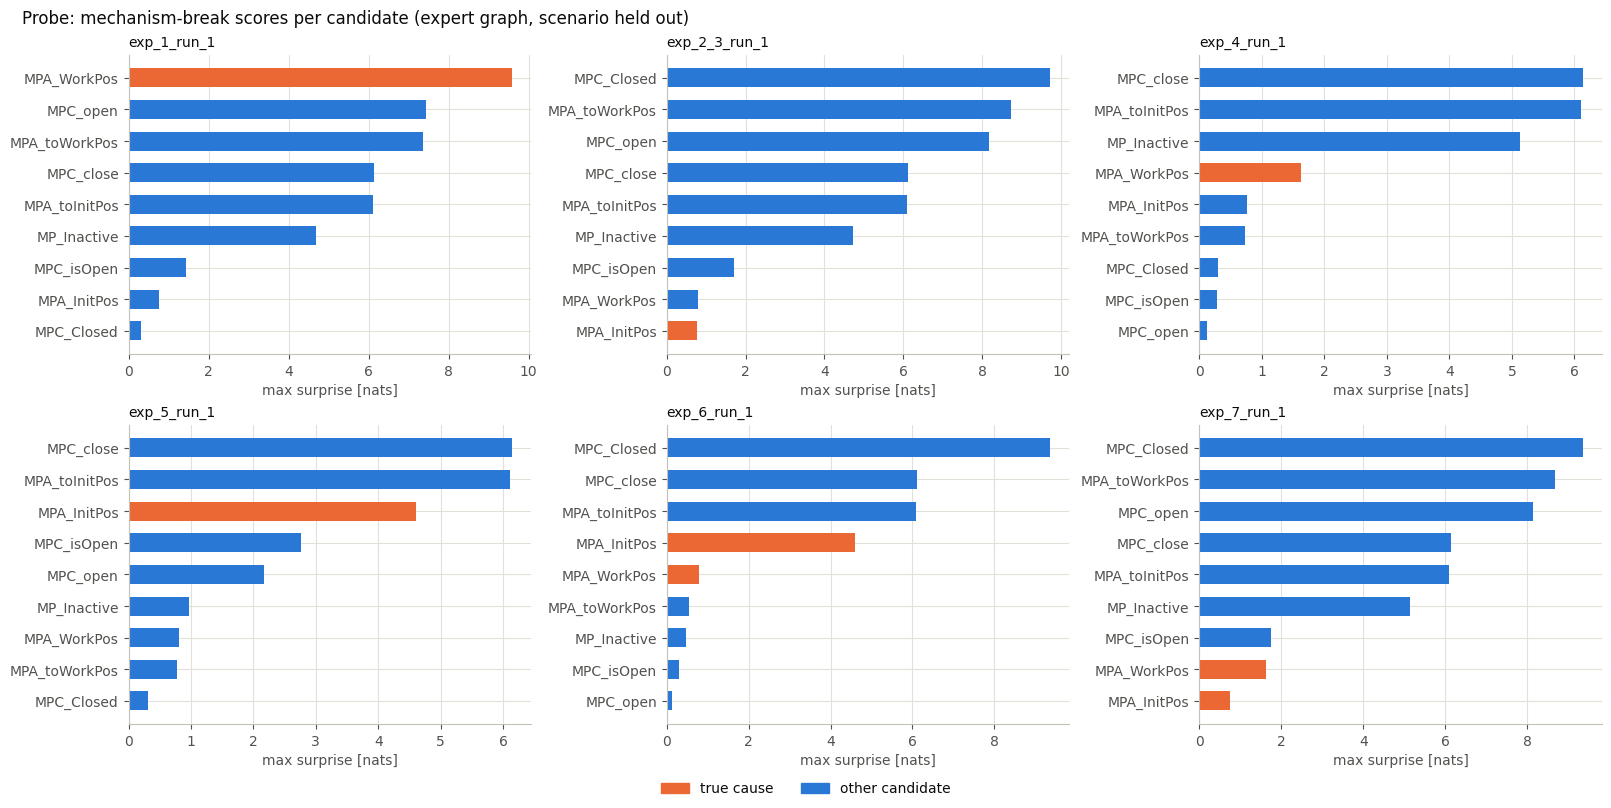

In [10]:
# figure 3: mechanism-break scores per candidate in one run of every scenario (expert graph)
metrics_e, rankings_e, _ = rca_results['expert']
scen = sorted(metrics_e.fold.unique())
fig, axes = plt.subplots(2, 3, figsize=(16, 8), layout='constrained')
for ax, fold in zip(axes.flat, scen):
    rid = metrics_e.loc[metrics_e.fold == fold, 'recording_id'].iloc[0]
    r = rankings_e[rankings_e.recording_id == rid].sort_values('rank')
    ax.barh(r.variable, r.score, color=[ev.COLORS[1] if c else ev.COLORS[0] for c in r.is_cause], height=0.6)
    ax.invert_yaxis()
    ax.set_xlabel('max surprise [nats]')
    ax.set_title(rid.removeprefix(SUBSYSTEM + '_'), fontsize=10)
fig.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=ev.COLORS[1], label='true cause'),
                    plt.Rectangle((0, 0), 1, 1, color=ev.COLORS[0], label='other candidate')], loc='outside lower center', ncol=2)
fig.suptitle('Probe: mechanism-break scores per candidate (expert graph, scenario held out)', x=0.01, ha='left')
ev.save_figure(fig, f'10_{SUBSYSTEM}_example_rankings')
plt.show()

## 6. Graph perturbations: does graph quality now matter?

The same perturbation design as notebook 09, evaluated on RCA and on the replay of the real manipulations. Counterfactuals are not applicable, see the top of the notebook.

In [11]:
# rca and replay quality for expert, discovered, empty and 45 perturbed graphs
events_fault = events[events.source == 'dig_twin']
changes = data.fault_variable_changes(events_fault, runs[runs.subsystem == SUBSYSTEM], experiments)
onset_steps = {(r, v): int(np.ceil(round(t / INTERVAL, 9))) for r, v, t in
               zip(changes.recording_id, changes.variable, changes.first_change_after_start_s) if not np.isnan(t)}
variants = {'expert': ('expert', 0.0, getters['expert'], expert),
            'discovered': ('discovered', np.nan, lambda fold: discovered_dag[f'discovered_without_{fold}'], discovered_dag['discovered']),
            'empty': ('empty', 1.0, getters['empty'], empty)}
for kind in KINDS:
    for fraction in FRACTIONS:
        for seed in SEEDS:
            g = ge.perturb_graph(expert, kind, fraction, seed)
            variants[f'{kind} {fraction:g} s{seed}'] = (kind, fraction, (lambda graph: (lambda fold: graph))(g), g)
rows = []
start = time.perf_counter()
for name, (kind, fraction, getter, graph) in variants.items():
    quality = ge.compare_graphs(graph, expert)
    downstream, _ = ev.evaluate_graph(getter, view_data, splits, manipulated, ALARMS, NODES, INTERVAL, onset_steps,
                                      n_samples=100, seed=SEED, counterfactuals=False)
    rows.append({'graph': name, 'kind': kind, 'fraction': fraction, **{k: quality[k] for k in ['skeleton_f1', 'directed_f1', 'shd']},
                 **{k: v for k, v in downstream.items() if not k.startswith('cf_')}})
print(f'{len(variants)} graphs in {time.perf_counter() - start:.0f} s')
perturbation = pd.DataFrame(rows)
ev.save_table(perturbation, f'10_{SUBSYSTEM}_perturbation_summary')
perturbation[perturbation.kind.isin(['expert', 'discovered', 'empty'])].round(3)

48 graphs in 78 s


,graph,kind,fraction,skeleton_f1,directed_f1,shd,map@3,top1,median_margin,replay_p_fires_all,replay_p_fires_supported,replay_delay_error_s
0,expert,expert,0.0,1.000,1.0,0,0.475,0.441,-1.537,0.613,0.613,14.75
1,discovered,discovered,NaN,0.125,0.0,15,0.559,0.235,-0.037,0.499,0.499,32.50
2,empty,empty,1.0,0.000,0.0,15,0.444,0.088,-0.029,0.499,0.499,32.50


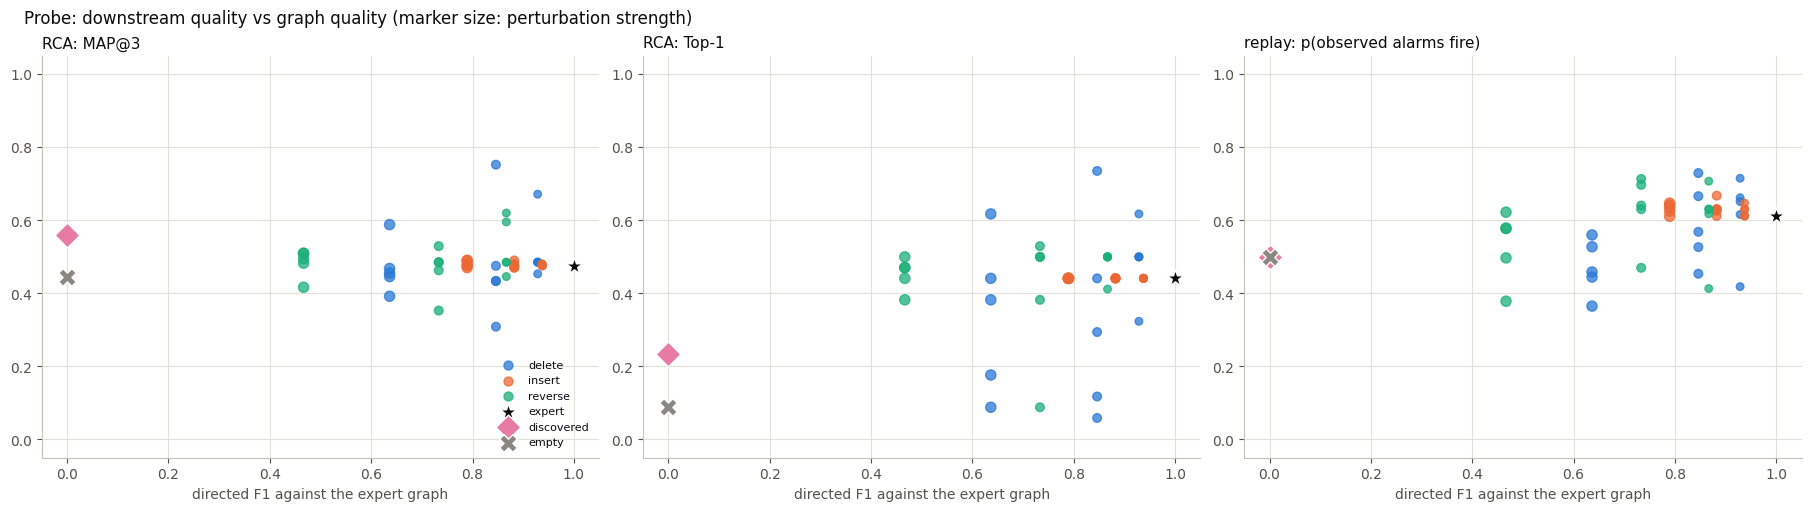

In [12]:
# figure 4: rca and replay quality against directed f1
kind_colors = {'delete': ev.COLORS[0], 'insert': ev.COLORS[1], 'reverse': ev.COLORS[2]}
ref_style = {'expert': ('*', ev.INK['primary']), 'discovered': ('D', ev.COLORS[4]), 'empty': ('X', ev.INK['muted'])}
panels = [('map@3', 'RCA: MAP@3'), ('top1', 'RCA: Top-1'), ('replay_p_fires_all', 'replay: p(observed alarms fire)')]
fig, axes = plt.subplots(1, 3, figsize=(18, 5), layout='constrained')
for ax, (metric, title) in zip(axes, panels):
    for kind in KINDS:
        d = perturbation[perturbation.kind == kind]
        ax.scatter(d.directed_f1, d[metric], s=24 + 60 * d.fraction, color=kind_colors[kind], alpha=0.75, label=kind)
    for name, (marker, color) in ref_style.items():
        r = perturbation.set_index('graph').loc[name]
        ax.scatter(r.directed_f1, r[metric], marker=marker, s=160, color=color, edgecolor=ev.INK['surface'], zorder=4, label=name)
    ax.set_xlabel('directed F1 against the expert graph')
    ax.set_ylim(-0.05, 1.05)
    ax.set_title(title)
axes[0].legend(loc='lower right', fontsize=8)
fig.suptitle('Probe: downstream quality vs graph quality (marker size: perturbation strength)', x=0.01, ha='left')
ev.save_figure(fig, f'10_{SUBSYSTEM}_downstream_vs_graph')
plt.show()

In [13]:
# spearman correlations with directed f1 over the perturbed graphs (bootstrap intervals over graphs)
perturbed = perturbation[perturbation.kind.isin(KINDS)]
rng = np.random.default_rng(SEED)
corr_rows = []
for target in ['map@3', 'top1', 'median_margin', 'replay_p_fires_all', 'replay_p_fires_supported']:
    x, y = perturbed.directed_f1.to_numpy(), perturbed[target].to_numpy()
    rho = stats.spearmanr(x, y).statistic if np.nanstd(y) > 0 else np.nan
    boot = []
    for _ in range(1000):
        idx = rng.integers(0, len(x), len(x))
        if np.std(x[idx]) > 0 and np.nanstd(y[idx]) > 0:
            boot.append(stats.spearmanr(x[idx], y[idx], nan_policy='omit').statistic)
    low, high = np.quantile(boot, [0.025, 0.975]) if boot else (np.nan, np.nan)
    corr_rows.append({'downstream': target, 'spearman_with_directed_f1': rho, 'ci_low': low, 'ci_high': high})
correlations = pd.DataFrame(corr_rows)
ev.save_table(correlations, f'10_{SUBSYSTEM}_correlations')
correlations.round(3)

,downstream,spearman_with_directed_f1,ci_low,ci_high
0,map@3,0.042,-0.265,0.332
1,top1,0.101,-0.179,0.369
2,median_margin,0.019,-0.300,0.315
3,replay_p_fires_all,0.354,0.064,0.574
4,replay_p_fires_supported,0.354,0.086,0.587


## 7. Findings

- **Discovery is weak on probe.**
  - Skeleton F1 0.52 (random: 0.19), directed F1 0.00: 7 of 8 discovered edges are undirected and the one oriented edge is reversed.
  - Probe signals form a command → arm position → cover sequence whose changes mostly fall into the same 0.5 s step, so PCMCI+ sees them as contemporaneous and cannot orient them.
  - The PLC also repeats the same sequence deterministically in normal operation, which makes many variables near-duplicates of each other. 9 expert edges are missed.
  - The normal regime (137k samples, 9 varying variables) takes 7 minutes.
- **The SCM needs the expert structure here.** With the expert graph, the probability given to the observed changes of the arm sensors rises from 0.004 (no parents) to 0.46–0.62 in unseen scenarios. The discovered acyclic graph has only one (reversed) edge and is close to the empty graph.
- **RCA now depends on the graph, in both directions** (34 held-out runs, 95% bootstrap intervals):

  | Graph | Top-1 | MAP@3 |
  |---|---|---|
  | expert | 0.44 [0.29, 0.59] | 0.475 |
  | empty | 0.09 [0.00, 0.21] | 0.444 |
  | chance (same candidates) | 0.14 | 0.21 |

  - **Work-position sensor faults** (exp_1, exp_4, `MPA_WorkPos`): the expert graph ranks the defective sensor first in 5 of 6 runs of each scenario (Top-1 0.83), because the sensor contradicts the movement command it depends on. **Initial-position sensor faults** (exp_2_3, exp_5) are harder (Top-1 0.25 and 0.33): the sensor drops while the arm is not being commanded, so its first-order mechanism finds the change only mildly surprising.
  - **Arm-stuck faults** (exp_6, exp_7, both sensors manipulated): the expert graph fails (MAP@3 0.00 and 0.10). Both sensors stay consistent *with each other*, and the downstream cover signals react to the stuck arm in ways their mechanisms have never seen, so they look more broken than the sensors.
  - **Without structure**, the true causes land in the top 3 in every run (Hit@3 1.00) but almost never first. They are simply among the variables that change.
  - The **discovered graph** behaves like the empty graph (Top-1 0.24, MAP@3 0.56).
- **Perturbations.** RCA quality does **not** follow directed F1 on probe (Spearman 0.04 [−0.27, 0.33] for MAP@3, 0.10 for Top-1). Several perturbed graphs do better than the expert graph on some scenarios and worse on others. The replay of the manipulations does follow graph quality (Spearman 0.35 [0.06, 0.57]).
- **Not applicable:** interventions and counterfactual recommendations. Probe faults are sensor defects; repairing a sensor restores a *mechanism* rather than setting a variable to a constant, and soft interventions are not implemented.
- *Thesis note.* The probe extension sharpens the coolant conclusion:
  - Graph structure *can* matter for locating a root cause, as soon as causes are variables that also change normally. But the effect is scenario-dependent and non-monotonic in graph F1.
  - Mechanism-break attribution assumes that only the intervened variable's mechanism breaks. When an intervention pushes the system into states never seen in training (the stuck arm), downstream mechanisms also look broken, and the method can rank effects above causes.
  - This is a limitation of the method, not of the graph.